In [ ]:
import os, sys
from pathlib import Path

ROOT = Path(r"C:\Users\gabyd\contract-clause-nlp") 
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print(os.getcwd())

C:\Users\gabyd\contract-clause-nlp


In [8]:
import json, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import softmax
from scipy.stats import binomtest
from sklearn.metrics import f1_score, accuracy_score
from src.data import load_ledgar
from src.evaluate import ece

ds, names = load_ledgar()
y = np.array(ds["test"]["label"])
ytr = np.array(ds["train"]["label"])

bert_prob = softmax(np.load("results/legalbert_e10_s42/test_logits.npy"), axis=1)
bert_pred = bert_prob.argmax(1)
base_pred = np.load("results/baseline/test_pred.npy")
print("Legal-BERT acc", accuracy_score(y, bert_pred), "| baseline acc", accuracy_score(y, base_pred))

Legal-BERT acc 0.8843 | baseline acc 0.8775


In [9]:
texts = np.array(ds["test"]["text"], dtype=object)
conf = bert_prob.max(1)
wrong = np.where(bert_pred != y)[0]
top = wrong[np.argsort(-conf[wrong])][:50]          # the 50 most confident mistakes
pd.DataFrame({
    "idx": top,
    "confidence": conf[top].round(3),
    "true_label": [names[i] for i in y[top]],
    "predicted_label": [names[i] for i in bert_pred[top]],
    "text": texts[top],
    "category": "",
    "comment": "",
}).to_csv("results/errors_top50.csv", index=False, encoding="utf-8-sig")   # utf-8-sig so Excel opens it cleanly

In [10]:
# McNemar (exact) on accuracy
base_ok, bert_ok = base_pred == y, bert_pred == y
b = int((base_ok & ~bert_ok).sum())   # only baseline right
c = int((~base_ok & bert_ok).sum())   # only Legal-BERT right
print(f"only baseline right: {b} | only Legal-BERT right: {c} | "
      f"McNemar exact p = {binomtest(b, b + c, 0.5).pvalue:.4f}")

# Paired bootstrap on the macro-F1 difference
rng = np.random.default_rng(0)
diffs = []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    diffs.append(f1_score(y[i], bert_pred[i], average="macro") - f1_score(y[i], base_pred[i], average="macro"))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"macro-F1 difference (Legal-BERT - baseline): {np.mean(diffs):+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}]")

only baseline right: 325 | only Legal-BERT right: 393 | McNemar exact p = 0.0124
macro-F1 difference (Legal-BERT - baseline): +0.0031, 95% CI [-0.0073, +0.0127]


In [11]:
buckets = json.load(open("results/class_buckets.json"))
name2id = {n: i for i, n in enumerate(names)}
rows = []
for bucket, labels in buckets.items():
    ids = [name2id[n] for n in labels]
    for model, pred in [("TF-IDF", base_pred), ("Legal-BERT", bert_pred)]:
        rows.append({"bucket": bucket, "model": model,
                     "macro_f1": f1_score(y, pred, labels=ids, average="macro", zero_division=0)})
by_bucket = pd.DataFrame(rows).pivot(index="bucket", columns="model", values="macro_f1").loc[["head", "torso", "tail"]]
by_bucket.to_csv("results/f1_by_bucket.csv"); by_bucket.round(3)

model,Legal-BERT,TF-IDF
bucket,,
head,0.912,0.900
torso,0.864,0.858
tail,0.755,0.759


Legal-BERT worse:
              class  train_n  f1_tfidf  f1_bert   gain
14           Books       23     1.000    0.800 -0.200
36  Enforceability      244     0.690    0.581 -0.109
50       Indemnity      271     0.735    0.630 -0.105
70          Powers      125     0.640    0.552 -0.088
37    Enforcements      201     0.685    0.600 -0.085 

Legal-BERT better:
              class  train_n  f1_tfidf  f1_bert   gain
72  Qualifications       47     0.571    0.667  0.095
35      Employment      308     0.713    0.809  0.096
69       Positions      190     0.603    0.714  0.111
95         Vesting      451     0.821    0.933  0.112
56   Jurisdictions      202     0.385    0.590  0.206


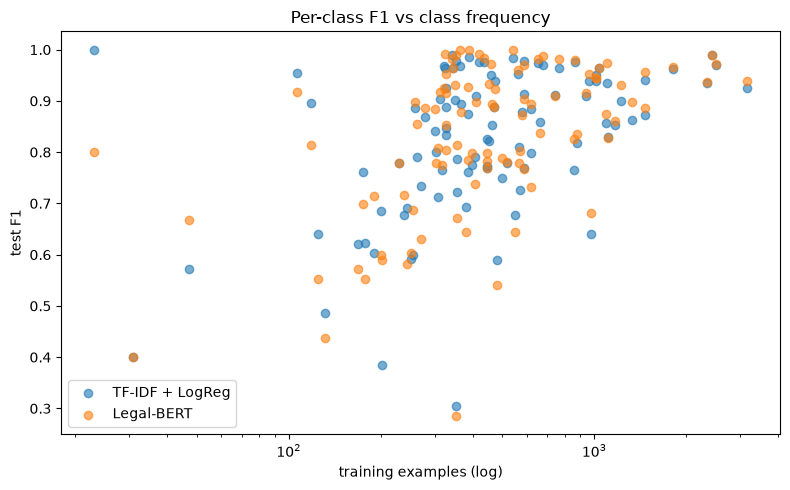

In [12]:
freq = np.bincount(ytr, minlength=len(names))
f1_base = f1_score(y, base_pred, labels=range(len(names)), average=None, zero_division=0)
f1_bert = f1_score(y, bert_pred, labels=range(len(names)), average=None, zero_division=0)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(freq, f1_base, alpha=.6, label="TF-IDF + LogReg")
ax.scatter(freq, f1_bert, alpha=.6, label="Legal-BERT")
ax.set_xscale("log"); ax.set_xlabel("training examples (log)"); ax.set_ylabel("test F1")
ax.set_title("Per-class F1 vs class frequency"); ax.legend()
plt.tight_layout(); plt.savefig("results/figures/f1_vs_frequency.png", dpi=150)

delta = pd.DataFrame({"class": names, "train_n": freq, "f1_tfidf": f1_base,
                      "f1_bert": f1_bert, "gain": f1_bert - f1_base}).sort_values("gain")
print("Legal-BERT worse:\n", delta.head(5).round(3), "\n\nLegal-BERT better:\n", delta.tail(5).round(3))

In [13]:
conf = pd.read_csv("results/legalbert_e10_s42/top_confusions.csv")
predicted = {("Assigns", "Assignments"), ("Costs", "Expenses"), ("Venues", "Governing Laws"),
             ("Consent To Jurisdiction", "Governing Laws"), ("Waivers", "No Waivers"),
             ("Applicable Laws", "Governing Laws")}
conf["predicted_in_EDA"] = [(t, p) in predicted or (p, t) in predicted for t, p in zip(conf.true, conf.predicted)]
conf.head(15)

,true,predicted,count,predicted_in_EDA
0,Applicable Laws,Governing Laws,33,True
1,Definitions,Defined Terms,24,False
2,Tax Withholdings,Withholdings,24,False
3,Authorizations,Authority,16,False
4,Successors,Binding Effects,16,False
5,Modifications,Amendments,15,False
6,No Waivers,Waivers,14,True
7,Integration,Entire Agreements,13,False
8,General,Payments,12,False
9,Withholdings,Tax Withholdings,12,False


In [14]:
vec, clf = joblib.load("models/baseline.joblib")
base_prob = clf.predict_proba(vec.transform(ds["test"]["text"]))
print(f"ECE baseline: {ece(base_prob, y):.3f} | ECE Legal-BERT: {ece(bert_prob, y):.3f}")

ECE baseline: 0.020 | ECE Legal-BERT: 0.084
